In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

os.makedirs(project_path, exist_ok=True)

print("Project folder ready!")
print("Folder location:", project_path)
print("Existing files:", os.listdir(project_path))


Project folder ready!
Folder location: /content/drive/MyDrive/Brain_Tumor_Project
Existing files: ['brain_tumor_model.keras', 'dataset']


In [3]:

import os

project_path = "/content/drive/MyDrive/Brain_Tumor_Project"

dataset_path = project_path + "/dataset"
model_path = project_path + "/brain_tumor_model.keras"

print("MODEL FILE")
print("Exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Size:", round(os.path.getsize(model_path) / (1024*1024), 2), "MB")

print("\nDATASET FOLDERS")

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        print("\n", folder)

        for category in sorted(os.listdir(folder_path)):
            category_path = os.path.join(folder_path, category)

            if os.path.isdir(category_path):
                count = len(os.listdir(category_path))
                print(category, ":", count, "images")


MODEL FILE
Exists: True
Size: 127.88 MB

DATASET FOLDERS

 Testing
glioma : 300 images
meningioma : 306 images
notumor : 405 images
pituitary : 300 images

 Training
glioma : 1321 images
meningioma : 1339 images
notumor : 1595 images
pituitary : 1457 images


In [4]:

import tensorflow as tf
import os

model_path = "/content/drive/MyDrive/Brain_Tumor_Project/brain_tumor_model.keras"

# Load saved model
model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

# Model information
model.summary()

# Check training progress saved in optimizer
print("\nOptimizer iterations:",
      model.optimizer.iterations.numpy())

# Check GPU
print("\nAvailable GPU:")
print(tf.config.list_physical_devices('GPU'))


Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,508,430 (127.82 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,954 (85.22 MB)


Optimizer iterations: 824

Available GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:

print("Optimizer iterations:",
      model.optimizer.iterations.numpy())

print("\nGPU Devices:")
print(tf.config.list_physical_devices('GPU'))

print("\nModel output classes:")
print(model.output_shape)


Optimizer iterations: 824

GPU Devices:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Model output classes:
(None, 4)


In [6]:
import tensorflow as tf

dataset_path = "/content/drive/MyDrive/Brain_Tumor_Project/dataset"

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + "/Testing",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

print("Class Names:", test_ds.class_names)

Found 1311 files belonging to 4 classes.
Class Names: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [7]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 397s 10s/step - accuracy: 0.8719 - loss: 0.3406
Test Loss: 0.34064120054244995
Test Accuracy: 87.19 %


41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 136ms/step
CLASSIFICATION REPORT:

              precision    recall  f1-score   support

      glioma       0.81      0.90      0.85       300
  meningioma       0.84      0.62      0.72       306
     notumor       0.90      0.97      0.93       405
   pituitary       0.93      0.97      0.95       300

    accuracy                           0.87      1311
   macro avg       0.87      0.86      0.86      1311
weighted avg       0.87      0.87      0.87      1311



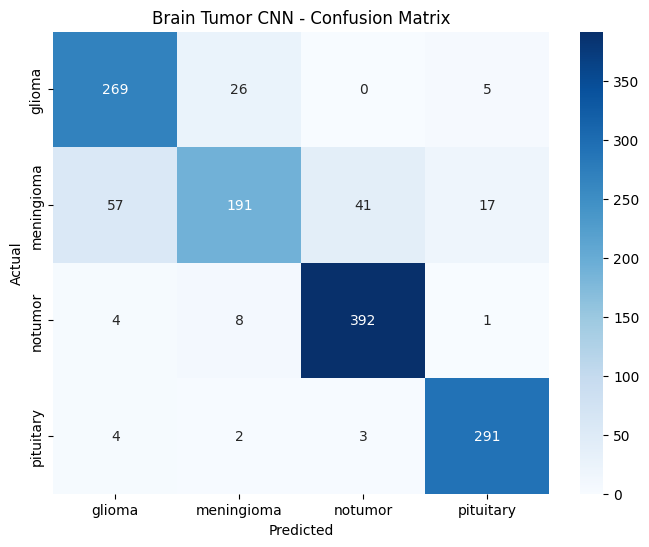

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Actual labels
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

# Model predictions
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# Class names
class_names = test_ds.class_names

# Classification Report
print("CLASSIFICATION REPORT:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Brain Tumor CNN - Confusion Matrix")
plt.show()

In [9]:
print("Confusion Matrix:\n")
print(cm)

print("\nCorrect Predictions:")
for i, name in enumerate(class_names):
    print(name, ":", cm[i][i], "/", sum(cm[i]))

Confusion Matrix:

[[269  26   0   5]
 [ 57 191  41  17]
 [  4   8 392   1]
 [  4   2   3 291]]

Correct Predictions:
glioma : 269 / 300
meningioma : 191 / 306
notumor : 392 / 405
pituitary : 291 / 300


In [10]:
import tensorflow as tf
import os

dataset_path = "/content/drive/MyDrive/Brain_Tumor_Project/dataset"

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + "/Training",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + "/Training",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

# Optimize data loading
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

# Save best model automatically
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/Brain_Tumor_Project/brain_tumor_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

# Continue training
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Found 5712 files belonging to 4 classes.
Using 4570 files for training.
Found 5712 files belonging to 4 classes.
Using 1142 files for validation.
Epoch 1/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9006 - loss: 0.2625
Epoch 1: val_loss improved from None to 0.24484, saving model to /content/drive/MyDrive/Brain_Tumor_Project/brain_tumor_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_Project/brain_tumor_best.keras
143/143 ━━━━━━━━━━━━━━━━━━━━ 1501s 10s/step - accuracy: 0.8941 - loss: 0.2739 - val_accuracy: 0.9168 - val_loss: 0.2448 - learning_rate: 0.0010
Epoch 2/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9020 - loss: 0.2497
Epoch 2: val_loss did not improve from 0.24484
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 105ms/step - accuracy: 0.9061 - loss: 0.2540 - val_accuracy: 0.8870 - val_loss: 0.2797 - learning_rate: 0.0010
Epoch 3/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9072 - loss: 0.2387
Epoch 3: val_loss did not im

In [11]:
import tensorflow as tf

best_model_path = "/content/drive/MyDrive/Brain_Tumor_Project/brain_tumor_best.keras"

best_model = tf.keras.models.load_model(best_model_path)

print("Best model loaded successfully!")

Best model loaded successfully!


In [12]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print("Final Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", test_loss)

41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9504 - loss: 0.1903
Final Test Accuracy: 95.04 %
Test Loss: 0.19029632210731506


In [13]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

predictions = best_model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

class_names = test_ds.class_names

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step
              precision    recall  f1-score   support

      glioma       0.98      0.90      0.94       300
  meningioma       0.90      0.90      0.90       306
     notumor       0.94      0.99      0.97       405
   pituitary       0.99      1.00      0.99       300

    accuracy                           0.95      1311
   macro avg       0.95      0.95      0.95      1311
weighted avg       0.95      0.95      0.95      1311

Confusion Matrix:
[[270  28   2   0]
 [  4 275  23   4]
 [  2   1 402   0]
 [  0   1   0 299]]
